In [ ]:
!pip install -q lightgbm shap holidays mlflow

## 1. Loading Libraries and Configuration :

In [ ]:
import os
import warnings
from datetime import date, timedelta

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)
START = "2015-01-01"

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

## 2. EDA and Data Prep:

In [ ]:
ODRE = ("https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/"
        "{}/exports/parquet?timezone=Europe%2FParis")
DATASETS = ["eco2mix-national-cons-def", "eco2mix-national-tr"]

raw = {}
for name in DATASETS:
    raw[name] = pd.read_parquet(ODRE.format(name))
    print(f"{name}: {raw[name].shape[0]:,} rows")
    print("  columns:", raw[name].columns.tolist())

display(raw[DATASETS[0]].head())

eco2mix-national-cons-def: 514,272 rows
  columns: ['perimetre', 'nature', 'date', 'heure', 'date_heure', 'consommation', 'prevision_j1', 'prevision_j', 'fioul', 'charbon', 'gaz', 'nucleaire', 'eolien', 'solaire', 'hydraulique', 'pompage', 'bioenergies', 'ech_physiques', 'taux_co2', 'ech_comm_angleterre', 'ech_comm_espagne', 'ech_comm_italie', 'ech_comm_suisse', 'ech_comm_allemagne_belgique', 'fioul_tac', 'fioul_cogen', 'fioul_autres', 'gaz_tac', 'gaz_cogen', 'gaz_ccg', 'gaz_autres', 'hydraulique_fil_eau_eclusee', 'hydraulique_lacs', 'hydraulique_step_turbinage', 'bioenergies_dechets', 'bioenergies_biomasse', 'bioenergies_biogaz']
eco2mix-national-tr: 8,160 rows
  columns: ['perimetre', 'nature', 'date', 'heure', 'date_heure', 'consommation', 'prevision_j1', 'prevision_j', 'fioul', 'charbon', 'gaz', 'nucleaire', 'eolien', 'eolien_terrestre', 'eolien_offshore', 'solaire', 'hydraulique', 'pompage', 'bioenergies', 'ech_physiques', 'taux_co2', 'ech_comm_angleterre', 'ech_comm_espagne', 'ec

,perimetre,nature,date,heure,date_heure,consommation,prevision_j1,prevision_j,fioul,charbon,...,gaz_tac,gaz_cogen,gaz_ccg,gaz_autres,hydraulique_fil_eau_eclusee,hydraulique_lacs,hydraulique_step_turbinage,bioenergies_dechets,bioenergies_biomasse,bioenergies_biogaz
0,France,Données consolidées,2026-08-31,23:45,2026-08-31 23:45:00+02:00,NaN,42850,42250,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,France,Données consolidées,2026-08-31,23:30,2026-08-31 23:30:00+02:00,43979.0,44200,43000,55.0,15.0,...,27.0,172,2969.0,51.0,2225.0,1405.0,681.0,485.0,403.0,291.0
2,France,Données consolidées,2026-08-31,23:15,2026-08-31 23:15:00+02:00,NaN,44850,43750,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,France,Données consolidées,2026-08-31,23:00,2026-08-31 23:00:00+02:00,45070.0,45500,44500,55.0,15.0,...,26.0,177,3016.0,51.0,2278.0,1869.0,806.0,484.0,402.0,292.0
4,France,Données consolidées,2026-08-31,22:45,2026-08-31 22:45:00+02:00,NaN,45100,44150,NaN,NaN,...,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
def to_points(df, source):
    # One row per reading: the local calendar day and the consumption in MW.
    if "perimetre" in df.columns:
        df = df[df["perimetre"].astype(str).str.lower() == "france"]
    if "date" in df.columns:
        day = pd.to_datetime(df["date"].astype(str)).dt.normalize()
    else:
        ts = pd.to_datetime(df["date_heure"])
        ts = (ts.dt.tz_localize("Europe/Paris", ambiguous="NaT", nonexistent="NaT")
              if ts.dt.tz is None else ts.dt.tz_convert("Europe/Paris"))
        day = ts.dt.tz_localize(None).dt.normalize()
    out = pd.DataFrame({
        "day": day.values,
        "consommation": pd.to_numeric(df["consommation"], errors="coerce").values,
        "source": source,
    })
    return out.dropna(subset=["day", "consommation"])

cons = to_points(raw["eco2mix-national-cons-def"], "consolidated")
rt = to_points(raw["eco2mix-national-tr"], "real-time")

# Keep real-time readings only for days after the consolidated data ends.
rt = rt[rt["day"] > cons["day"].max()]
points = pd.concat([cons, rt], ignore_index=True)
points = points[points["day"] >= START]

for src, g in points.groupby("source"):
    print(f"{src:>12}: {g['day'].min().date()} to {g['day'].max().date()}")

consolidated: 2015-01-01 to 2026-08-31
   real-time: 2026-09-01 to 2026-11-24


In [ ]:
# Paris daily mean temperature. The archive runs a few days behind today.
last_day = min(points["day"].max().date(), date.today() - timedelta(days=3))
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=48.85&longitude=2.35"
       f"&start_date={START}&end_date={last_day}"
       "&daily=temperature_2m_mean&timezone=Europe/Paris")
w = requests.get(url, timeout=120).json()
weather = pd.DataFrame({
    "day": pd.to_datetime(w["daily"]["time"]),
    "temp": w["daily"]["temperature_2m_mean"],
}).set_index("day")

print(f"weather: {weather.index.min().date()} to {weather.index.max().date()}, "
      f"{weather['temp'].isna().sum()} missing values")

weather: 2015-01-01 to 2026-11-20, 0 missing values


In [ ]:
agg = (points.groupby(["day", "source"])["consommation"]
       .agg(load_mw="mean", n_readings="count")
       .reset_index())
agg["typical"] = agg.groupby("source")["n_readings"].transform("median")
short = agg["n_readings"] < 0.9 * agg["typical"]
print(f"Dropped {short.sum()} days with too few readings:",
      agg.loc[short, "day"].dt.date.tolist()[:10])
agg = agg[~short]

assert not agg["day"].duplicated().any(), "duplicate days"

daily = (agg.set_index("day")[["load_mw"]]
         .join(weather, how="inner")
         .sort_index())
daily["load_gw"] = daily.pop("load_mw") / 1000
daily = daily[["load_gw", "temp"]]

# Put every calendar day on the index, so a shift of 1 always means yesterday.
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing = full_range.difference(daily.index)
daily = daily.reindex(full_range)
daily.index.name = "day"
print(f"{len(daily):,} days from {daily.index.min().date()} to {daily.index.max().date()}, "
      f"{len(missing)} missing days")
daily.head()

Dropped 1 days with too few readings: [datetime.date(2026, 11, 24)]
4,342 days from 2015-01-01 to 2026-11-20, 0 missing days


,load_gw,temp
day,,
2015-01-01,67.242375,-0.7
2015-01-02,69.001896,4.9
2015-01-03,64.094208,6.3
2015-01-04,58.878667,4.0
2015-01-05,71.274979,0.3


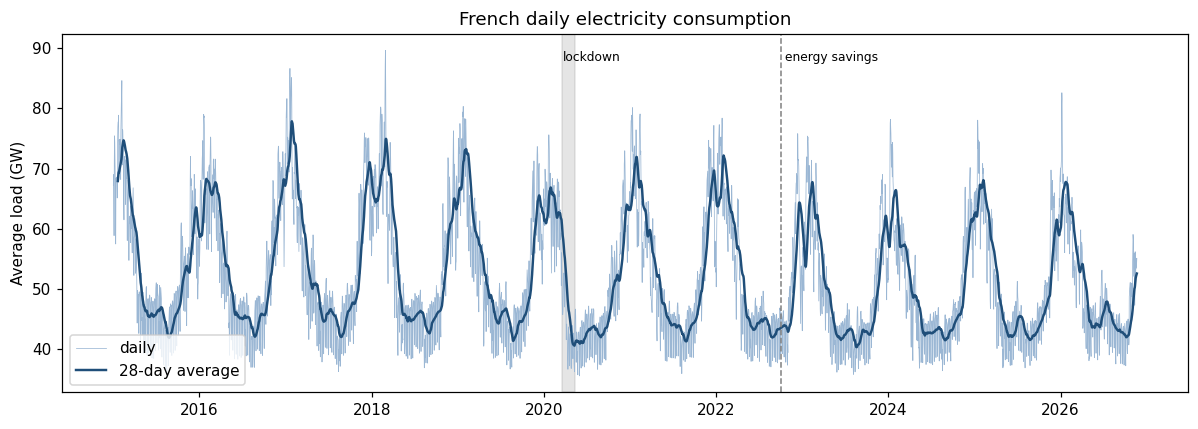

Average load by year (GW):
day
2015    54.0
2016    54.7
2017    54.7
2018    54.3
2019    53.7
2020    50.8
2021    53.5
2022    51.4
2023    49.7
2024    50.1
2025    50.7
2026    49.6


In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["load_gw"], lw=0.5, color="#9bb7d4", label="daily")
ax.plot(daily.index, daily["load_gw"].rolling(28, min_periods=20).mean(),
        lw=1.6, color="#1f4e79", label="28-day average")
ax.axvspan(pd.Timestamp("2020-03-17"), pd.Timestamp("2020-05-11"), color="grey", alpha=0.2)
ax.text(pd.Timestamp("2020-03-20"), ax.get_ylim()[1] * 0.97, "lockdown", fontsize=8, va="top")
ax.axvline(pd.Timestamp("2022-10-01"), color="grey", ls="--", lw=1)
ax.text(pd.Timestamp("2022-10-20"), ax.get_ylim()[1] * 0.97, "energy savings", fontsize=8, va="top")
ax.set_ylabel("Average load (GW)")
ax.set_title("French daily electricity consumption")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("figures/01_daily_load.png")
plt.show()

print("Average load by year (GW):")
print(daily["load_gw"].groupby(daily.index.year).mean().round(1).to_string())

In [ ]:
# Test years = the last two full calendar years in the data.
end = daily.index.max()
last_full = end.year if (end.month, end.day) == (12, 31) else end.year - 1
TEST_YEARS = [last_full - 1, last_full]

for y in TEST_YEARS:
    n = daily.loc[str(y), "load_gw"].notna().sum()
    print(f"{y}: {n} days with data" + ("" if n >= 355 else "  <- check this year"))
print("Test years:", TEST_YEARS)

2024: 366 days with data
2025: 365 days with data
Test years: [2024, 2025]


## 3. Setting Baselines for Comparison:

In [ ]:
def metrics(y_true, y_pred):
    err = y_true - y_pred
    return {
        "MAE (GW)": np.mean(np.abs(err)),
        "RMSE (GW)": np.sqrt(np.mean(err ** 2)),
        "MAPE (%)": 100 * np.mean(np.abs(err) / y_true),
    }

baselines = pd.DataFrame({
    "actual": daily["load_gw"],
    "Naive": daily["load_gw"].shift(1),
    "Seasonal naive": daily["load_gw"].shift(7),
})

rows = []
for y in TEST_YEARS:
    b = baselines.loc[str(y)].dropna()
    for name in ["Naive", "Seasonal naive"]:
        rows.append({"model": name, "test year": y, **metrics(b["actual"], b[name])})
baseline_results = pd.DataFrame(rows)
baseline_results.round(2)

,model,test year,MAE (GW),RMSE (GW),MAPE (%)
0,Naive,2024,2.30,3.09,4.70
1,Seasonal naive,2024,3.12,4.67,5.81
2,Naive,2025,2.29,3.06,4.63
3,Seasonal naive,2025,3.27,4.91,6.04


In [ ]:
FR_HOLIDAYS = holidays.France(years=range(2015, date.today().year + 2))

def build_features(daily):
    d = daily.copy()
    d["lag_1"] = d["load_gw"].shift(1)
    d["lag_7"] = d["load_gw"].shift(7)
    d["lag_14"] = d["load_gw"].shift(14)
    d["roll_7"] = d["load_gw"].shift(1).rolling(7).mean()
    d["dow"] = d.index.dayofweek
    d["month"] = d.index.month
    d["doy"] = d.index.dayofyear
    d["is_holiday"] = d.index.map(lambda x: x in FR_HOLIDAYS).astype(int)
    d["hdd"] = (15.5 - d["temp"]).clip(lower=0)
    d["cdd"] = (d["temp"] - 22).clip(lower=0)
    return d.dropna()

FEATURES_ALL = ["lag_1", "lag_7", "lag_14", "roll_7", "dow", "month", "doy",
                "is_holiday", "temp", "hdd", "cdd"]
FEATURES_NO_WEATHER = [f for f in FEATURES_ALL if f not in ("temp", "hdd", "cdd")]
FEATURES_MONO = [f for f in FEATURES_ALL if f != "temp"]

feat = build_features(daily)
print(f"{len(feat):,} rows, {len(FEATURES_ALL)} features")
feat[FEATURES_ALL + ["load_gw"]].tail()

4,328 rows, 11 features


,lag_1,lag_7,lag_14,roll_7,dow,month,doy,is_holiday,temp,hdd,cdd,load_gw
day,,,,,,,,,,,,
2026-11-16,51.206010,55.984448,54.073979,53.169457,0,11,320,0,10.2,5.3,0.0,55.130302
2026-11-17,55.130302,53.684010,56.637344,53.047436,1,11,321,0,13.7,1.8,0.0,54.166802
2026-11-18,54.166802,47.330833,59.071896,53.116406,2,11,322,0,11.4,4.1,0.0,53.471250
2026-11-19,53.471250,52.876812,58.301917,53.993609,3,11,323,0,10.6,4.9,0.0,54.456552
2026-11-20,54.456552,56.201135,57.823167,54.219286,4,11,324,0,9.7,5.8,0.0,55.110146


In [ ]:
# Leakage check: rebuild the features using only data up to day t.
# If row t is identical, no feature looked into the future.
check_days = feat.loc[str(TEST_YEARS[0])].index[[10, 100, 200]]
for t in check_days:
    cut = build_features(daily.loc[:t])
    pd.testing.assert_series_equal(cut.loc[t, FEATURES_ALL], feat.loc[t, FEATURES_ALL])
print("Leakage check passed on", [t.date() for t in check_days])

Leakage check passed on [datetime.date(2024, 1, 11), datetime.date(2024, 4, 10), datetime.date(2024, 7, 19)]


## 4. Training LightGBM:

In [ ]:
FOLDS = [{"train_end": y - 2, "val": y - 1, "test": y} for y in TEST_YEARS]
pd.DataFrame(FOLDS).rename(columns={"train_end": "train up to", "val": "early-stopping year",
                                    "test": "test year"})

,train up to,early-stopping year,test year
0,2022,2023,2024
1,2023,2024,2025


In [ ]:
VERSIONS = {
    "LightGBM": {"features": FEATURES_ALL},
    "LightGBM, no weather": {"features": FEATURES_NO_WEATHER},
    # LightGBM does not allow monotone constraints with the L1 objective,
    # so this version uses L2 (squared error) instead.
    "LightGBM, monotone": {"features": FEATURES_MONO, "objective": "l2",
                           "monotone_constraints": [1 if f == "hdd" else 0 for f in FEATURES_MONO]},
}

def fit_lgbm(X_train, y_train, X_val, y_val, objective="l1", **extra):
    model = lgb.LGBMRegressor(
        objective=objective, learning_rate=0.03, n_estimators=3000,
        num_leaves=31, min_child_samples=20, colsample_bytree=0.8,
        random_state=SEED, verbose=-1, **extra)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

models, preds, rows = {}, [], []
years = feat.index.year
for fold in FOLDS:
    tr, va, te = years <= fold["train_end"], years == fold["val"], years == fold["test"]
    for name, cfg in VERSIONS.items():
        cols = cfg["features"]
        extra = {k: v for k, v in cfg.items() if k != "features"}
        model = fit_lgbm(feat.loc[tr, cols], feat.loc[tr, "load_gw"],
                         feat.loc[va, cols], feat.loc[va, "load_gw"], **extra)
        p = model.predict(feat.loc[te, cols])
        models[(name, fold["test"])] = model
        preds.append(pd.DataFrame({"model": name, "test year": fold["test"],
                                   "actual": feat.loc[te, "load_gw"], "pred": p}))
        rows.append({"model": name, "test year": fold["test"],
                     **metrics(feat.loc[te, "load_gw"].values, p),
                     "trees": model.best_iteration_})

preds = pd.concat(preds)
lgbm_results = pd.DataFrame(rows)

In [ ]:
# One results table: every model, both test years, and the average.
results = pd.concat([baseline_results, lgbm_results.drop(columns="trees")])
avg = results.groupby("model", sort=False).mean(numeric_only=True).assign(**{"test year": "average"})
results = pd.concat([results, avg.reset_index()])
order = ["Naive", "Seasonal naive"] + list(VERSIONS)
results["model"] = pd.Categorical(results["model"], order)
results = results.sort_values(
    ["model", "test year"],
    key=lambda s: s.cat.codes if s.name == "model" else s.astype(str)).reset_index(drop=True)
results.round(3).to_csv("results/results.csv", index=False)

table = results.pivot(index="model", columns="test year", values="MAE (GW)").round(2)
print("MAE (GW) by test year")
display(table)
display(results.round(2))

best_baseline = results.query("`test year` == 'average' and model in ['Naive', 'Seasonal naive']")["MAE (GW)"].min()
lgbm_avg = results.query("`test year` == 'average' and model == 'LightGBM'")["MAE (GW)"].iloc[0]
print(f"LightGBM average MAE {lgbm_avg:.2f} GW vs best baseline {best_baseline:.2f} GW "
      f"({100 * (1 - lgbm_avg / best_baseline):.0f}% lower)")

MAE (GW) by test year


test year,2024,2025,average
model,,,
Naive,2.30,2.29,2.30
Seasonal naive,3.12,3.27,3.19
LightGBM,0.86,0.92,0.89
"LightGBM, no weather",1.18,1.28,1.23
"LightGBM, monotone",0.93,0.89,0.91


,model,test year,MAE (GW),RMSE (GW),MAPE (%)
0,Naive,2024,2.30,3.09,4.70
1,Naive,2025,2.29,3.06,4.63
2,Naive,average,2.30,3.07,4.67
3,Seasonal naive,2024,3.12,4.67,5.81
4,Seasonal naive,2025,3.27,4.91,6.04
5,Seasonal naive,average,3.19,4.79,5.92
6,LightGBM,2024,0.86,1.21,1.64
7,LightGBM,2025,0.92,1.29,1.74
8,LightGBM,average,0.89,1.25,1.69
9,"LightGBM, no weather",2024,1.18,1.77,2.23


LightGBM average MAE 0.89 GW vs best baseline 2.30 GW (61% lower)


## 5.Using SHAP for Explaining Behaviour:

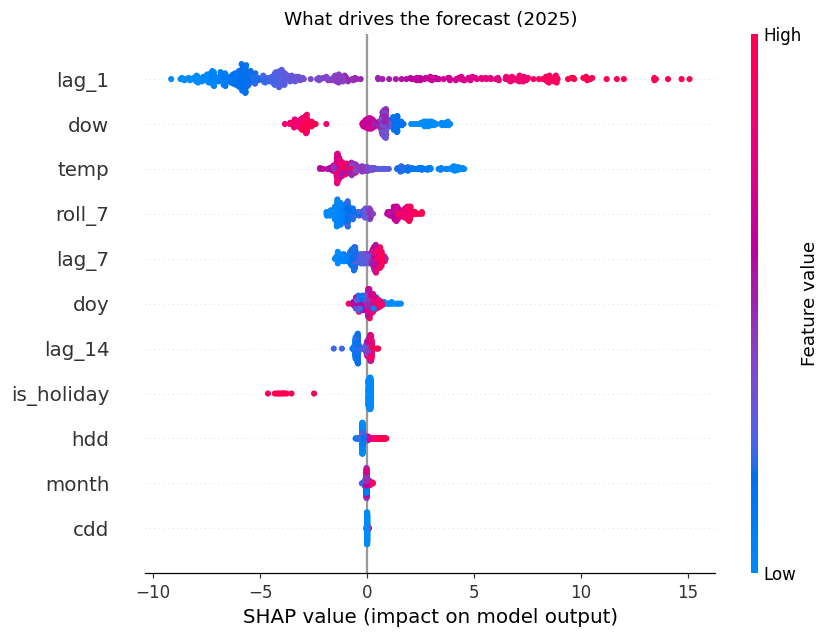

In [ ]:
TEST_YEAR = TEST_YEARS[-1]
model = models[("LightGBM", TEST_YEAR)]
X_test = feat.loc[str(TEST_YEAR), FEATURES_ALL]

explainer = shap.TreeExplainer(model)
sv = explainer(X_test)

shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title(f"What drives the forecast ({TEST_YEAR})")
plt.tight_layout()
plt.savefig("figures/02_shap_beeswarm.png", bbox_inches="tight")
plt.show()

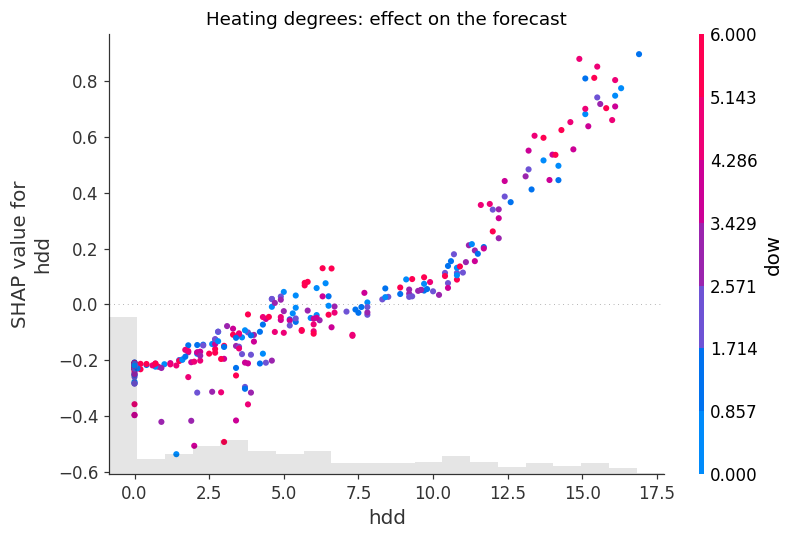

Below 15 degrees C, each degree colder adds about 0.46 GW to the forecast.


In [ ]:
shap.plots.scatter(sv[:, "hdd"], color=sv[:, "dow"], show=False)
plt.title("Heating degrees: effect on the forecast")
plt.tight_layout()
plt.savefig("figures/03_shap_heating.png", bbox_inches="tight")
plt.show()

# How many GW does one colder degree add? Add up the three temperature
# features (they share credit) and fit a line on days below 15 degrees.
temp_effect = sv[:, "temp"].values + sv[:, "hdd"].values + sv[:, "cdd"].values
cold = X_test["temp"].values < 15
slope = np.polyfit(X_test["temp"].values[cold], temp_effect[cold], 1)[0]
print(f"Below 15 degrees C, each degree colder adds about {-slope:.2f} GW to the forecast.")

Coldest test day: 2025-01-14 (-1.4 degrees C), actual 78.0 GW


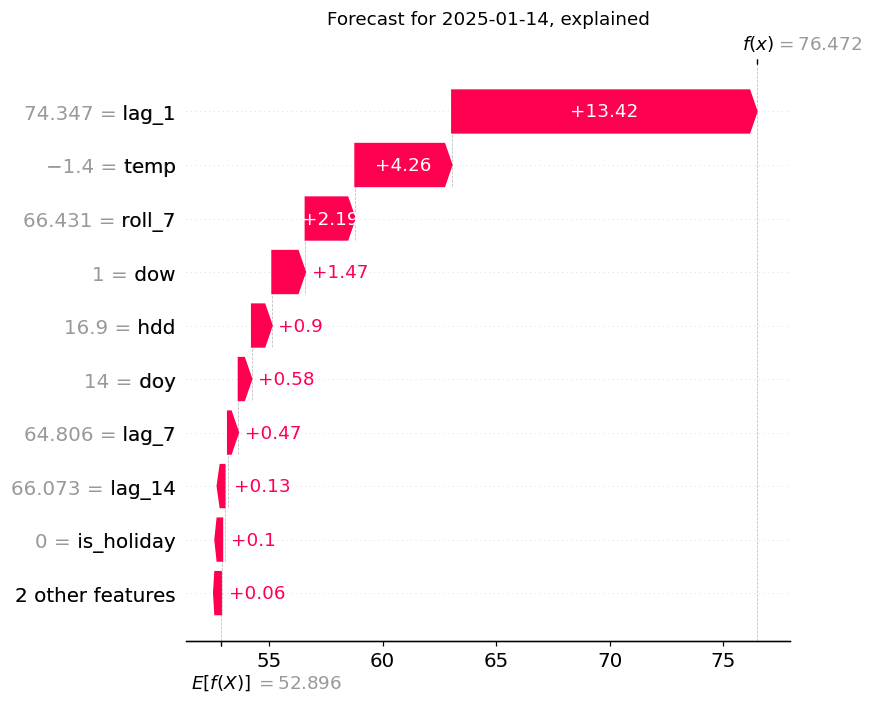

In [ ]:
i = int(np.argmin(X_test["temp"].values))
coldest = X_test.index[i]
print(f"Coldest test day: {coldest.date()} ({X_test['temp'].iloc[i]:.1f} degrees C), "
      f"actual {feat.loc[coldest, 'load_gw']:.1f} GW")

shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.title(f"Forecast for {coldest.date()}, explained")
plt.tight_layout()
plt.savefig("figures/04_shap_coldest_day.png", bbox_inches="tight")
plt.show()

## 6. Checking the Errors:

In [ ]:
p = preds[preds["model"] == "LightGBM"].copy()
p["error"] = p["actual"] - p["pred"]
p["abs_error"] = p["error"].abs()
p = p.join(feat[["temp", "is_holiday"]])
p["weekday"] = p.index.day_name()

top = (p.sort_values("abs_error", ascending=False).head(10)
       [["weekday", "actual", "pred", "error", "temp", "is_holiday"]].round(2))
top["what happened"] = ""   # fill in by hand after looking each day up
top.to_csv("results/top_errors.csv")
top

,weekday,actual,pred,error,temp,is_holiday,what happened
day,,,,,,,
2024-01-17,Wednesday,70.08,76.20,-6.11,1.2,0,
2024-01-18,Thursday,68.62,74.20,-5.58,-0.3,0,
2025-02-17,Monday,65.59,70.38,-4.80,1.8,0,
2025-01-22,Wednesday,68.78,73.53,-4.75,5.0,0,
2024-01-15,Monday,72.07,76.68,-4.61,1.0,0,
2025-11-24,Monday,63.13,67.39,-4.25,7.1,0,
2025-01-05,Sunday,57.27,61.22,-3.95,9.9,0,
2025-01-09,Thursday,63.75,67.64,-3.89,6.0,0,
2024-12-24,Tuesday,58.50,62.38,-3.88,7.0,0,


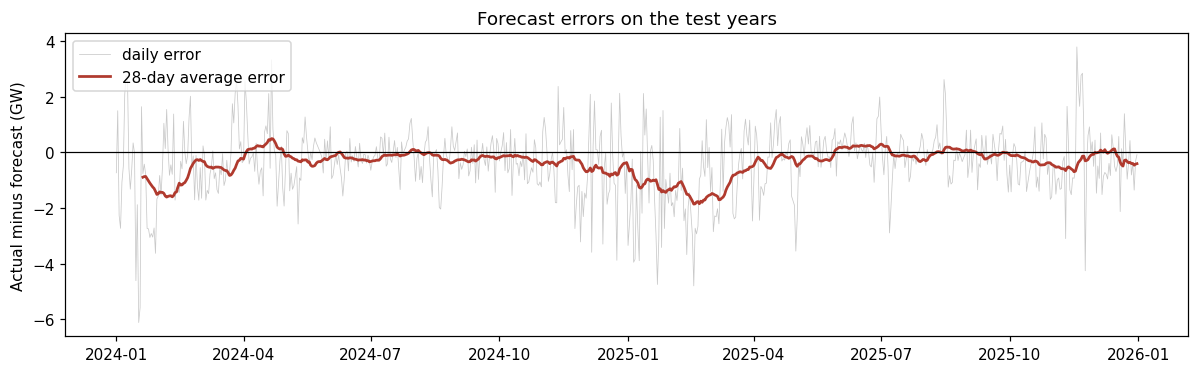

In [ ]:
err = p["error"].sort_index()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(err.index, err, lw=0.5, color="#c9c9c9", label="daily error")
ax.plot(err.index, err.rolling(28, min_periods=20).mean(), lw=1.8, color="#b03a2e",
        label="28-day average error")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Actual minus forecast (GW)")
ax.set_title("Forecast errors on the test years")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/05_error_drift.png")
plt.show()

## 7. Tracking Experiments with MLflow:

Every model from step 4 becomes an MLflow run with its settings, its scores, the trained model and a sample input. The two baselines are logged too, so all five versions can be compared side by side. The best version is then registered in the MLflow model registry and loaded back by name, the way a production service would load it. Runs are stored in `mlflow.db`, models and files in `mlruns/`.

In [ ]:
import logging
import mlflow
import mlflow.lightgbm
from mlflow.models import infer_signature

logging.getLogger("mlflow").setLevel(logging.ERROR)
# Our features never contain missing values, so this schema hint does not apply.
warnings.filterwarnings("ignore", message=".*Inferred schema contains integer.*")

mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENT = "france-power-d1"
mlflow.set_experiment(EXPERIMENT)

DATA_PARAMS = {
    "data_start": str(feat.index.min().date()),
    "data_end": str(feat.index.max().date()),
    "target": "daily mean load (GW)",
    "weather": "Paris daily mean temperature (Open-Meteo)",
}
LGBM_PARAMS = {
    "learning_rate": 0.03, "max_trees": 3000, "early_stopping_rounds": 100,
    "num_leaves": 31, "min_child_samples": 20, "colsample_bytree": 0.8, "seed": SEED,
}

In [ ]:
def log_scores(df):
    # Average scores over the test years, under short metric names.
    s = df[["MAE (GW)", "RMSE (GW)", "MAPE (%)"]].mean()
    mlflow.log_metrics({"mae_gw": s["MAE (GW)"], "rmse_gw": s["RMSE (GW)"], "mape_pct": s["MAPE (%)"]})

# Baselines: no model to save, only their scores.
for name in ["Naive", "Seasonal naive"]:
    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"level": "version", "model_type": "baseline"})
        mlflow.log_params({**DATA_PARAMS, "test_years": ",".join(map(str, TEST_YEARS))})
        log_scores(baseline_results[baseline_results["model"] == name])

# LightGBM: one parent run per version, one child run per fold with its model.
model_uris = {}
for name, cfg in VERSIONS.items():
    cols = cfg["features"]
    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"level": "version", "model_type": "lightgbm"})
        mlflow.log_params({
            **DATA_PARAMS, **LGBM_PARAMS,
            "objective": cfg.get("objective", "l1"),
            "monotone_hdd": "monotone_constraints" in cfg,
            "n_features": len(cols),
            "features": ",".join(cols),
            "test_years": ",".join(map(str, TEST_YEARS)),
        })
        log_scores(lgbm_results[lgbm_results["model"] == name])

        for fold in FOLDS:
            y = fold["test"]
            model = models[(name, y)]
            X_te = feat.loc[str(y), cols]
            row = lgbm_results[(lgbm_results["model"] == name) & (lgbm_results["test year"] == y)].iloc[0]
            with mlflow.start_run(run_name=f"{name} | test {y}", nested=True):
                mlflow.set_tags({"level": "fold", "model_type": "lightgbm"})
                mlflow.log_params({"train_end": fold["train_end"],
                                   "early_stopping_year": fold["val"], "test_year": y})
                mlflow.log_metrics({"mae_gw": row["MAE (GW)"], "rmse_gw": row["RMSE (GW)"],
                                    "mape_pct": row["MAPE (%)"], "best_iteration": row["trees"]})
                info = mlflow.lightgbm.log_model(
                    model, name="model",
                    signature=infer_signature(X_te, model.predict(X_te)),
                    input_example=X_te.head(3))
                model_uris[(name, y)] = info.model_uri

        if name == "LightGBM":
            # The figures and tables describe the main model, so they go with its run.
            mlflow.log_artifacts("figures", artifact_path="figures")
            mlflow.log_artifacts("results", artifact_path="results")

print(f"Logged {2 + len(VERSIONS)} versions and {len(model_uris)} models to experiment '{EXPERIMENT}'")

Logged 5 versions and 6 models to experiment 'france-power-d1'


In [ ]:
# Read the comparison back from MLflow, best first.
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string="tags.level = 'version'",
    order_by=["metrics.mae_gw ASC", "attributes.start_time DESC"],
)
runs = runs.drop_duplicates("tags.mlflow.runName")   # keep the latest run of each version
comparison = (runs[["tags.mlflow.runName", "tags.model_type", "metrics.mae_gw",
                    "metrics.rmse_gw", "metrics.mape_pct"]]
              .rename(columns={"tags.mlflow.runName": "version", "tags.model_type": "type",
                               "metrics.mae_gw": "MAE (GW)", "metrics.rmse_gw": "RMSE (GW)",
                               "metrics.mape_pct": "MAPE (%)"})
              .round(2).reset_index(drop=True))
comparison

,version,type,MAE (GW),RMSE (GW),MAPE (%)
0,LightGBM,lightgbm,0.89,1.25,1.69
1,"LightGBM, monotone",lightgbm,0.91,1.26,1.75
2,"LightGBM, no weather",lightgbm,1.23,1.79,2.31
3,Naive,baseline,2.30,3.07,4.67
4,Seasonal naive,baseline,3.19,4.79,5.92


**Register the best model.** The version with the lowest average MAE is registered as `france-power-d1` with the alias `champion`. We register its latest fold (trained up to the year before the last test year). In production you would retrain it on all the data first and register that.

In [ ]:
MODEL_NAME = "france-power-d1"
client = mlflow.MlflowClient()

best = comparison[comparison["type"] == "lightgbm"].iloc[0]["version"]
mv = mlflow.register_model(model_uris[(best, TEST_YEARS[-1])], MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", mv.version)
client.update_model_version(
    MODEL_NAME, mv.version,
    description=f"{best}, trained up to {TEST_YEARS[-1] - 2}, tested on {TEST_YEARS[-1]}. "
                f"Average MAE {comparison.set_index('version').loc[best, 'MAE (GW)']} GW.")
print(f"Registered '{best}' as {MODEL_NAME} version {mv.version}, alias 'champion'")

# Load it back by name, as a service would, and check it gives the same forecasts.
champion = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")
X_check = feat.loc[str(TEST_YEARS[-1]), VERSIONS[best]["features"]]
same = np.allclose(champion.predict(X_check), models[(best, TEST_YEARS[-1])].predict(X_check))
assert same, "registered model does not match the trained model"
print(f"Champion loaded from the registry: {len(X_check)} forecasts identical to the trained model")

Registered 'LightGBM' as france-power-d1 version 1, alias 'champion'
Champion loaded from the registry: 365 forecasts identical to the trained model


Successfully registered model 'france-power-d1'.
Created version '1' of model 'france-power-d1'.


## 8. Saving Results and Versions for Repeatability:

In [ ]:
from importlib.metadata import version
pkgs = ["pandas", "numpy", "lightgbm", "shap", "scikit-learn", "matplotlib", "holidays",
        "requests", "pyarrow", "mlflow"]
with open("requirements.txt", "w") as f:
    f.write("\n".join(f"{p}=={version(p)}" for p in pkgs) + "\n")
print(open("requirements.txt").read())

def to_markdown(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "| " + " | ".join("---" for _ in cols) + " |"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(f"{v:.2f}" if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

readme_table = results[results["test year"] == "average"].drop(columns="test year")
print(to_markdown(readme_table))

pandas==2.2.3
numpy==2.4.6
lightgbm==4.6.0
shap==0.54.1
scikit-learn==1.6.1
matplotlib==3.10.0
holidays==0.108
requests==2.32.4
pyarrow==23.0.1
mlflow==3.18.0

| model | MAE (GW) | RMSE (GW) | MAPE (%) |
| --- | --- | --- | --- |
| Naive | 2.30 | 3.07 | 4.67 |
| Seasonal naive | 3.19 | 4.79 | 5.92 |
| LightGBM | 0.89 | 1.25 | 1.69 |
| LightGBM, no weather | 1.23 | 1.79 | 2.31 |
| LightGBM, monotone | 0.91 | 1.26 | 1.75 |


In [ ]:
# Colab only: download the figures, tables, versions and MLflow files in one zip.
try:
    from google.colab import files
    os.system("zip -qr outputs.zip figures results requirements.txt mlflow.db mlruns")
    files.download("outputs.zip")
except ImportError:
    print("Not in Colab: files are in figures/, results/, mlflow.db and mlruns/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>